In [ ]:

# Import essential libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Import machine learning tools
from sklearn.datasets import fetch_california_housing

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

# Load the California Housing dataset

housing = fetch_california_housing()

# Convert the dataset into a Pandas DataFrame
df = pd.DataFrame(
    housing.data,
    columns=housing.feature_names
)

# Add the target variable (house price)
df["Price"] = housing.target

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [ ]:

# Display the first 5 rows
df.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
5,4.0368,52.0,4.761658,1.103627,413.0,2.139896,37.85,-122.25,2.697
6,3.6591,52.0,4.931907,0.951362,1094.0,2.128405,37.84,-122.25,2.992
7,3.1200,52.0,4.797527,1.061824,1157.0,1.788253,37.84,-122.25,2.414
8,2.0804,42.0,4.294118,1.117647,1206.0,2.026891,37.84,-122.26,2.267
9,3.6912,52.0,4.970588,0.990196,1551.0,2.172269,37.84,-122.25,2.611


In [ ]:
# Check missing values in each column
df.isnull().sum()





,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
Price,0


In [ ]:
# Count duplicate rows
df.duplicated().sum()

np.int64(0)

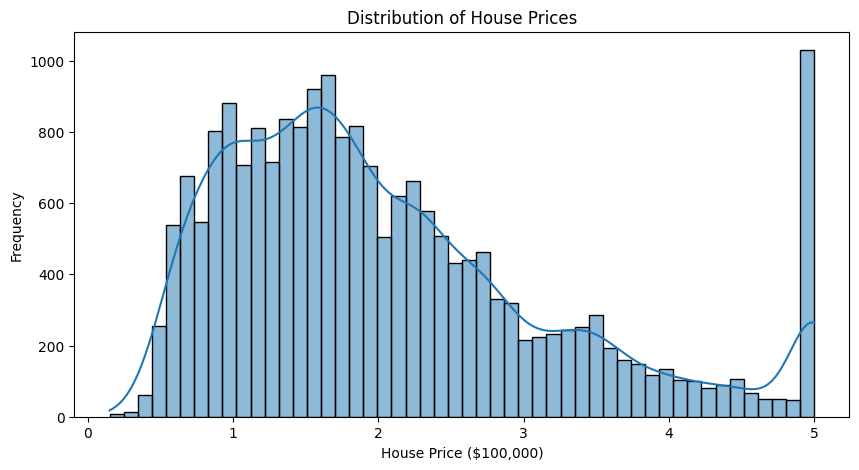

In [ ]:
# Visualize house price distribution

plt.figure(figsize=(10, 5))

sns.histplot(df["Price"], bins=50, kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("House Price ($100,000)")
plt.ylabel("Frequency")

plt.show()

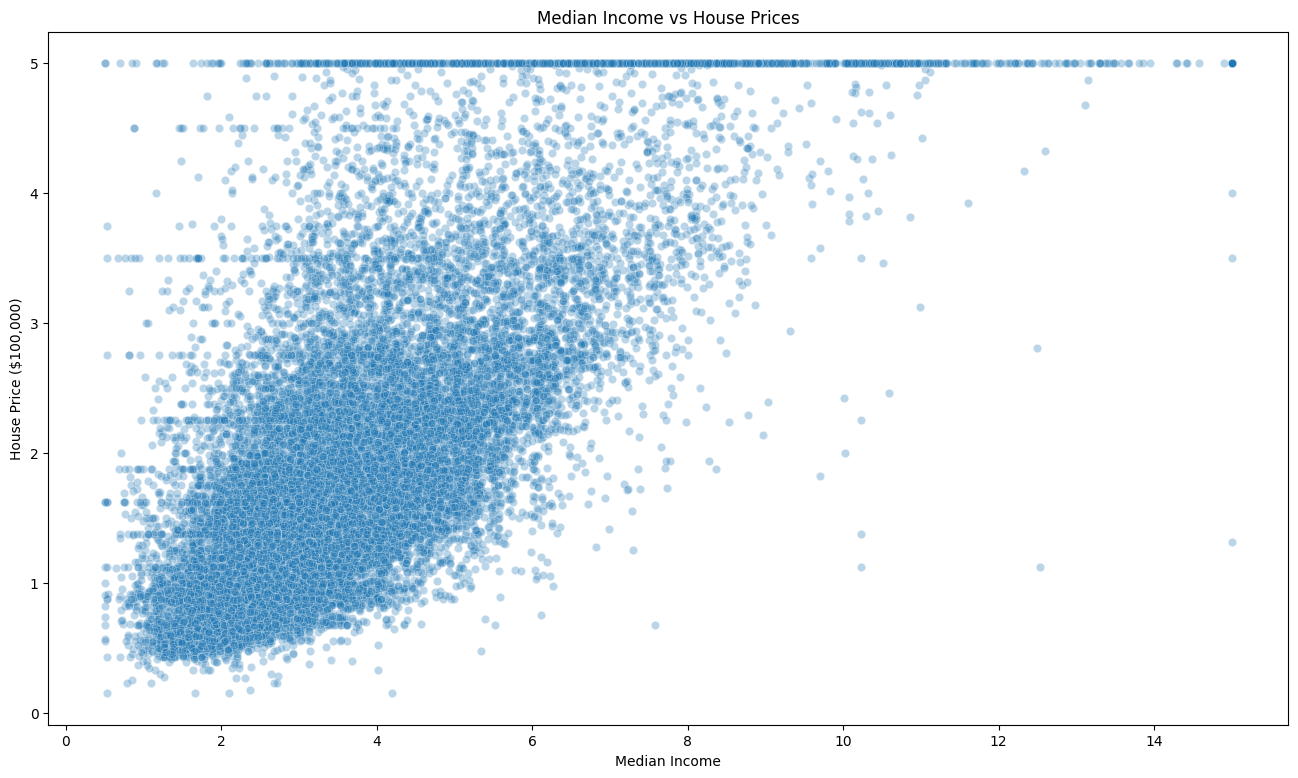

In [ ]:

# Visualize the relationship between income and house prices

plt.figure(figsize=(16, 9))

sns.scatterplot(
    data=df,
    x="MedInc",
    y="Price",
    alpha=0.3
)

plt.title("Median Income vs House Prices")
plt.xlabel("Median Income")
plt.ylabel("House Price ($100,000)")

plt.show()


In [ ]:
# Calculate correlations between all numerical columns

correlation = df.corr()

# Display correlations with house prices
correlation["Price"].sort_values(ascending=False)

,Price
Price,1.000000
MedInc,0.688075
AveRooms,0.151948
HouseAge,0.105623
AveOccup,-0.023737
Population,-0.024650
Longitude,-0.045967
AveBedrms,-0.046701
Latitude,-0.144160


In [ ]:

# Separate features and target

X = df.drop("Price", axis=1)
y = df["Price"]

# Display their shapes

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (20640, 8)
Target shape: (20640,)


In [ ]:

# Import train_test_split

from sklearn.model_selection import train_test_split

# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Display dataset sizes

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)



Training features: (16512, 8)
Testing features: (4128, 8)
Training targets: (16512,)
Testing targets: (4128,)


In [ ]:
# bulding the odel
# Import Linear Regression

from sklearn.linear_model import LinearRegression

# Create the model

model = LinearRegression()

print("Linear Regression model created!")


Linear Regression model created!


In [ ]:

# Tain the model using training data

model.fit(X_train, y_train)

print("Model training completed!")


Model training completed!


In [ ]:

# Predict house prices using testing data

y_pred = model.predict(X_test)

# Display the first 10 predictions

print("First 10 predicted house prices:")
print(y_pred[:10])


First 10 predicted house prices:
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725 2.01175367
 2.64550005 2.16875532 2.74074644 3.91561473]


In [ ]:

# Comparing privacy to check accuracy

comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

comparison.head(80)


,Actual Price,Predicted Price
0,0.47700,0.719123
1,0.45800,1.764017
2,5.00001,2.709659
3,2.18600,2.838926
4,2.78000,2.604657
...,...,...
75,1.46500,2.008220
76,4.05000,3.326979
77,1.89600,2.080108
78,1.64400,2.408994


In [ ]:

# Import evaluation metrics

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Calculate performance metrics

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

# Display results

print("Model Evaluation Results")
print("------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


Model Evaluation Results
------------------------
MAE: 0.5332001304956561
MSE: 0.5558915986952438
RMSE: 0.745581383012776
R2 Score: 0.5757877060324512


In [ ]:

# Import Random Forest

from sklearn.ensemble import RandomForestRegressor

# Initialize the model

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")


Random Forest training completed!


In [ ]:

# Generate predictions using Random Forest

rf_pred = rf_model.predict(X_test)

# Display first 10 predictions

print("First 10 Random Forest predictions:")
print(rf_pred[:10])


First 10 Random Forest predictions:
[0.5095    0.74161   4.9232571 2.52961   2.27369   1.64692   2.37605
 1.66932   2.7729706 4.9134589]


In [ ]:

# Calculate Random Forest evaluation metrics

rf_mae = mean_absolute_error(y_test, rf_pred)

rf_mse = mean_squared_error(y_test, rf_pred)

rf_rmse = np.sqrt(rf_mse)

rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Evaluation Results")
print("--------------------------------")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)



Random Forest Evaluation Results
--------------------------------
MAE: 0.3275425684593025
MSE: 0.2553684927247781
RMSE: 0.5053399773665033
R2 Score: 0.8051230593157366


In [ ]:

# Import hyperparameter tuning tools

from sklearn.model_selection import RandomizedSearchCV

# Define possible Random Forest settings

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 20, 30],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": [1.0, "sqrt"]
}

# Initialize RandomizedSearchCV

random_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=-1),
    param_distributions=param_grid,
    n_iter=8,
    cv=3,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Search for the best configuration using training data

random_search.fit(X_train, y_train)

# Display the best settings

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation RMSE:")
print(-random_search.best_score_)


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Parameters:
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 30}

Best Cross-Validation RMSE:
0.5033617516347406


In [ ]:

# Get the best tuned model

best_model = random_search.best_estimator_

# Generate predictions

best_pred = best_model.predict(X_test)

# Calculate evaluation metrics

best_mae = mean_absolute_error(y_test, best_pred)

best_mse = mean_squared_error(y_test, best_pred)

best_rmse = np.sqrt(best_mse)

best_r2 = r2_score(y_test, best_pred)

# Display results

print("Tuned Random Forest Results")
print("---------------------------")
print("MAE:", best_mae)
print("MSE:", best_mse)
print("RMSE:", best_rmse)
print("R2 Score:", best_r2)


Tuned Random Forest Results
---------------------------
MAE: 0.3282686009476908
MSE: 0.24625611296164626
RMSE: 0.49624199032492833
R2 Score: 0.812076903431918


## Final Conclusion

This project explored the application of supervised machine learning for predicting house prices using the California Housing Dataset.

Three regression models were developed and evaluated: Linear Regression, Random Forest Regression, and Tuned Random Forest Regression.

The Linear Regression model achieved an R² score of 0.5758, while the standard Random Forest model achieved 0.8051. After hyperparameter tuning using RandomizedSearchCV with three-fold cross-validation, the tuned Random Forest achieved an improved R² score of 0.8121.

The tuned model also achieved an RMSE of 0.4962 and an MAE of 0.3283, indicating that its predictions were reasonably close to the actual house values.

Overall, Random Forest performed considerably better than Linear Regression on this dataset. Hyperparameter tuning provided a further improvement in overall predictive performance, although the MAE increased slightly.

This project demonstrated the importance of exploratory data analysis, data preprocessing, model selection, hyperparameter optimization, and model evaluation in developing machine learning solutions.

### Limitations

- The dataset represents California housing data from 1990 and does not reflect current property prices.
- Some target values are capped at approximately $500,000.
- The model may not generalize to other geographical regions.
- Predictions are estimates and should not be treated as actual property valuations.

### Future Improvements

- Experiment with additional regression algorithms.
- Perform more extensive hyperparameter optimization.
- Investigate feature importance and model interpretability.
- Develop an interactive house price prediction application using Streamlit.

In [ ]:

# Generate final GitHub README

readme = f"""
# California House Price Prediction

## Project Overview

A machine learning project that predicts median
house values using the California Housing Dataset.

The project compares three regression models and
investigates the effect of hyperparameter tuning.

## Dataset

- Dataset: California Housing Dataset
- Observations: {len(df):,}
- Input features: {X.shape[1]}
- Target: Median house value
- Target unit: $100,000

## Technologies

- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn

## Project Workflow

1. Dataset loading and inspection
2. Exploratory Data Analysis
3. Missing value and duplicate checks
4. Correlation analysis
5. Feature and target separation
6. Train-test split (80/20)
7. Linear Regression
8. Random Forest Regression
9. Hyperparameter tuning
10. Model evaluation and comparison

## Model Performance

| Model | MAE | MSE | RMSE | R2 |
|---|---:|---:|---:|---:|
| Linear Regression | {mae:.4f} | {mse:.4f} | {rmse:.4f} | {r2:.4f} |
| Random Forest | {rf_mae:.4f} | {rf_mse:.4f} | {rf_rmse:.4f} | {rf_r2:.4f} |
| Tuned Random Forest | {best_mae:.4f} | {best_mse:.4f} | {best_rmse:.4f} | {best_r2:.4f} |

## Best Model

Tuned Random Forest Regression.

- MAE: {best_mae:.4f}
- MSE: {best_mse:.4f}
- RMSE: {best_rmse:.4f}
- R2 Score: {best_r2:.4f}

## Hyperparameter Tuning

RandomizedSearchCV was used with three-fold
cross-validation and eight sampled configurations.

Best parameters:

```python
{random_search.best_params_}
```

## Conclusion

Random Forest outperformed Linear Regression
on the test dataset.

Hyperparameter tuning improved the R2 score
from {rf_r2:.4f} to {best_r2:.4f}.

The project demonstrates the use of supervised
machine learning, regression, model evaluation,
and hyperparameter optimization.

## Limitations

- The dataset represents California housing data from 1990.
- Some house values are capped at approximately $500,000.
- Results may not generalize to other locations.
- Predictions are estimates, not guaranteed property values.

## Future Improvements

- Feature importance analysis.
- Additional regression algorithms.
- More extensive hyperparameter tuning.
- Streamlit prediction application.

## Author

Machine Learning Portfolio Project
"""

with open("README.md", "w") as file:
    file.write(readme)

print("Final README created successfully!")


Final README created successfully!


In [ ]:
from google.colab import files
files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import joblib

joblib.dump(best_model, "house_price_model.pkl")

['house_price_model.pkl']